# A spatial multi-omic portrait of survival outcome for clear cell renal cell carcinoma, Meyer et al., 2026

# Figure 5 and Figure S9

Python data analysis scripts for re-creating Figure 5 and Figure S9. 

# Software requirements

In [ ]:
# Run with Python 3.10.0
import glob
import os
import urllib.request
import pickle
from collections import Counter
import numpy as np #v.2.2.4
import pandas as pd #v.2.2.3
import seaborn as sns #v.0.13.2
import matplotlib.pyplot as plt #v.3.10.1
import matplotlib as mpl
from matplotlib.colors import ListedColormap, BoundaryNorm
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, precision_recall_curve, auc, roc_curve) #v.1.6.1
from sklearn.preprocessing import label_binarize
from sklearn.metrics import ConfusionMatrixDisplay

# Read data

In [ ]:
# Available from Zenodo - DOI: https://doi.org/10.5281/zenodo.23661454
# File paths ("PATH_TO") have to be adjusted by the user
PATH_TO = "PATH_TO"

# # EXAMPLE DOWNLOAD CODE
# os.makedirs(PATH_TO, exist_ok=True)
# zenodo_files = [
#    "discovery_HE_uniclam_train_results.csv",
#    "discovery_HE_uni_kmeans_silhouette.csv",
#    "discovery_HE_uni_kmeans_umap.csv.gz",
#]
#for f in zenodo_files:
#    local_path = os.path.join(PATH_TO, f)
#    if not os.path.exists(local_path):
#        urllib.request.urlretrieve(f"https://zenodo.org/records/23661454/files/{f}?download=1", local_path)

## UNI CLAM training results
HE_train_results = pd.read_csv(os.path.join(PATH_TO, "discovery_HE_uniclam_train_results.csv"))

## Other
sil_df = pd.read_csv(os.path.join(PATH_TO, "discovery_HE_uni_kmeans_silhouette.csv"))
umap_df = pd.read_csv(os.path.join(PATH_TO, "discovery_HE_uni_kmeans_umap.csv.gz"))

# Figure 5

## 5B

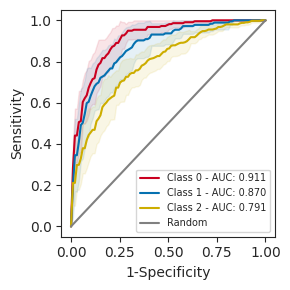

In [18]:
# Display ROC curves for each class
mean_fpr = np.linspace(0, 1, 100)
mpl.rcParams['pdf.fonttype'] = 42   # editable text in PDF
mpl.rcParams['ps.fonttype'] = 42
sns.set_style('ticks')
prob_cols = sorted([c for c in HE_train_results.columns if c.startswith('prob_class')],
                   key=lambda c: int(c.replace('prob_class', '')))
classes = list(range(len(prob_cols)))
tprs = {k: [] for k in classes}
aucs = {k: [] for k in classes}

for _, g in HE_train_results.groupby(['run', 'split']):
    y_bin = label_binarize(g['label'], classes=classes)
    p = g[prob_cols].to_numpy()
    for k in classes:
        fpr, tpr, _ = roc_curve(y_bin[:, k], p[:, k])
        interp_tpr = np.interp(mean_fpr, fpr, tpr)
        interp_tpr[0] = 0.0
        tprs[k].append(interp_tpr)
        aucs[k].append(roc_auc_score(y_bin[:, k], p[:, k]))

fig_roc, ax = plt.subplots(figsize=(3, 3))
class_colors = {0: '#CA0020', 1: '#0571B0', 2: '#cdad00'}

for k in classes:
    mean_tpr = np.mean(tprs[k], axis=0)
    std_tpr = np.std(tprs[k], axis=0)
    ax.plot(mean_fpr, mean_tpr, color=class_colors[k],
            label=f'Class {k} - AUC: {np.mean(aucs[k]):.3f}')
    ax.fill_between(mean_fpr,
                    np.clip(mean_tpr - std_tpr, 0, 1),
                    np.clip(mean_tpr + std_tpr, 0, 1),
                    color=class_colors[k], alpha=0.1)

ax.plot([0, 1], [0, 1], color='grey', linestyle='-', label='Random')
ax.set_xlabel('1-Specificity')
ax.set_ylabel('Sensitivity')
ax.legend(loc='lower right', fontsize=7)
plt.tight_layout()
plt.show()

## 5C

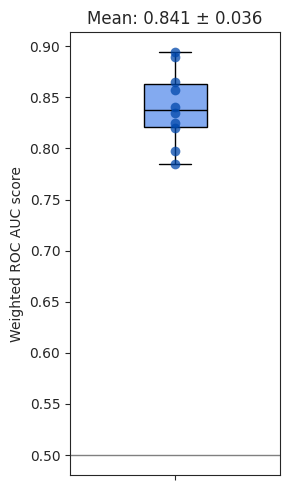

In [16]:
# Display boxplots for metrics across folds
y_all = HE_train_results['label'].to_numpy()
mfc = HE_train_results['label'].mode()[0]
baseline_f1_mfc = f1_score(y_all, np.full_like(y_all, mfc), average='weighted')

def fold_metrics(df):
    y = df['label'].to_numpy()
    p = df[prob_cols].to_numpy()
    y_pred = p.argmax(axis=1)
    y_bin = label_binarize(y, classes=classes)

    pr_aucs = []
    for k in classes:
        prec, rec, _ = precision_recall_curve(y_bin[:, k], p[:, k])
        pr_aucs.append(auc(rec, prec))

    return {
        'Accuracy': accuracy_score(y, y_pred),
        'Precision (weighted)': precision_score(y, y_pred, average='weighted', zero_division=0),
        'Recall (weighted)': recall_score(y, y_pred, average='weighted', zero_division=0),
        'F1 Score (weighted)': f1_score(y, y_pred, average='weighted'),
        'AUC_PR': np.mean(pr_aucs),
        'AUC_ROC': roc_auc_score(y_bin, p, multi_class='ovr', average='weighted'),
    }

metrics_df = pd.DataFrame([
    {'run': run, 'split': split, **fold_metrics(g)}
    for (run, split), g in HE_train_results.groupby(['run', 'split'])
])

# Plot
## Weighted ROC AUC score
box_color_rgba = (100/255, 149/255, 237/255, 0.8)  # #6495ED, alpha 0.8

def plot_metric(col, ylabel, baseline, figsize=(3, 5)):
    fig, ax = plt.subplots(figsize=figsize)
    sns.boxplot(
        y=metrics_df[col], ax=ax, width=0.3, color=None,
        boxprops=dict(facecolor=box_color_rgba, edgecolor='black'),
        medianprops={'color': 'black'}, whiskerprops={'color': 'black'},
        capprops={'color': 'black'}, showfliers=False
    )
    sns.stripplot(y=metrics_df[col], ax=ax, color='#0047AB', alpha=0.75, size=7, jitter=False)
    ax.axhline(baseline, color='grey', linestyle='-', linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_title(f"Mean: {metrics_df[col].mean():.3f} ± {metrics_df[col].std():.3f}")
    plt.tight_layout()
    return fig

fig_auc = plot_metric('AUC_ROC', 'Weighted ROC AUC score', baseline=0.5)
plt.show()

# Figure S9

## S9B

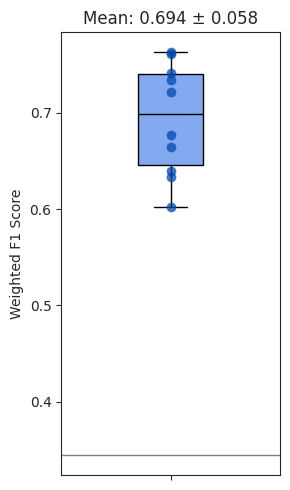

In [17]:
# Plot
## Weighted F1 Score
fig_auc = plot_metric('F1 Score (weighted)', 'Weighted F1 Score', baseline=baseline_f1_mfc)
plt.show()

## S9D

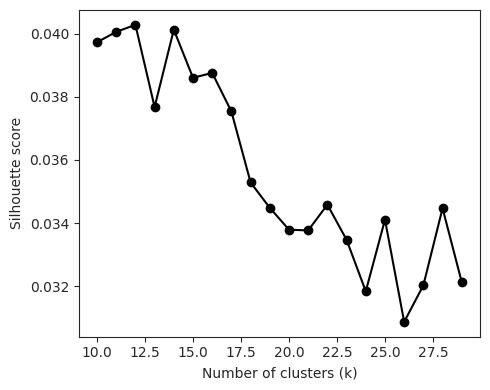

In [27]:
# Silhouette width
fig_sil, ax = plt.subplots(figsize=(5, 4))
ax.plot(sil_df["k"], sil_df["silhouette"], marker="o", color="black")
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Silhouette score")
plt.tight_layout()
plt.show()

## S9E

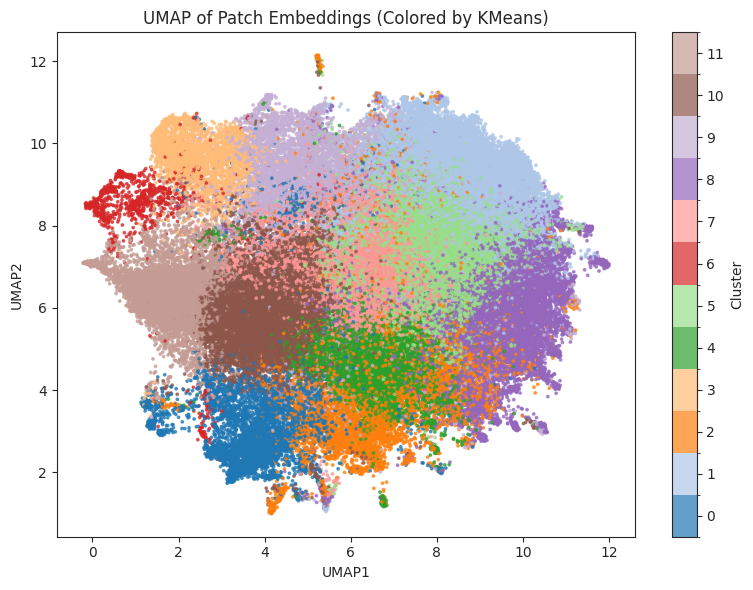

In [28]:
# UMAP visualization
k = umap_df["cluster"].nunique()
cmap = ListedColormap(plt.cm.tab20.colors[:k])
norm = BoundaryNorm(np.arange(-0.5, k + 0.5, 1), cmap.N)

fig_umap, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(umap_df["UMAP1"], umap_df["UMAP2"], c=umap_df["cluster"],
                cmap=cmap, norm=norm, s=3, alpha=0.7)
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
ax.set_title("UMAP of Patch Embeddings (Colored by KMeans)")
fig_umap.colorbar(sc, ax=ax, ticks=np.arange(k)).set_label("Cluster")
plt.tight_layout()
plt.show()